# crispyx tutorial

Genome-wide CRISPR screens routinely produce datasets with hundreds of thousands of cells and tens of thousands of genes. Standard single-cell toolkits (Scanpy, Pertpy) load the entire count matrix into memory, which can require 30–100+ GB of RAM. **crispyx** streams data directly from on-disk AnnData `.h5ad` files so that QC, normalisation, pseudo-bulk aggregation, and differential expression all run without materialising the full matrix. These memory savings assume sufficient free disk space for streaming intermediates and output files — crispyx warns automatically if that looks tight, and `cx.estimate_disk_usage(...)` can check usage before a large run (see the Disk space section of [Working with large data](../large_data.rst)).

This tutorial walks through a complete crispyx workflow on the included Adamson subset dataset, covering:

1. Data loading and inspection
2. Data preparation utilities
3. Quality control
4. Subsampling and downsampling
5. Streaming normalisation
6. Dimension reduction (PCA, KNN, UMAP)
7. Pseudo-bulk aggregation
8. Differential expression (Wilcoxon and NB-GLM)
9. LFC shrinkage
10. Plotting

For the full API, see the [API reference](../api.rst); each step's guide page is linked from the [Quick start](../quickstart.rst).

## Setup

Install the project in editable mode (with the optional `test` extras) to make the package importable:

```bash
pip install -e .[test]
```

## 1. Load the dataset

This tutorial uses the included Adamson subset stored at `data/Adamson_subset.h5ad`. `cx.read_h5ad_ondisk` returns a read-only wrapper — the expression matrix stays on disk.

In [1]:
import sys
from pathlib import Path
import pandas as pd

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'src'))
DATA_PATH = ROOT / 'data' / 'Adamson_subset.h5ad'
OUTPUT_DIR = Path('tutorial_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import crispyx as cx
print(f'crispyx {cx.__version__}')

if not DATA_PATH.exists():
    raise FileNotFoundError(f'Expected dataset at {DATA_PATH}')

crispyx 0.2.9


### Inspect metadata

The `obs` and `var` accessors expose `head` and `load` helpers so you can preview metadata without materialising the entire object.

In [2]:
adata_ro = cx.read_h5ad_ondisk(DATA_PATH)
adata_ro

AnnData object with n_obs × n_vars = 1716 × 11630 backed at '../../data/Adamson_subset.h5ad'
    obs: 'perturbation', 'n_genes', 'dataset', 'celltype'
    var: 'Ensembl_ID'
First obs rows:
                 perturbation  n_genes  dataset celltype
Cell_barcodes                                           
AAACATACAAGATG-1      control     2914  Adamson     K562
AAACATTGCATTGG-1      control     3999  Adamson     K562
AAACGGCTAATGCC-1       AMIGO3     3947  Adamson     K562
AAAGACGAACTCAG-1      control     2713  Adamson     K562
AAAGAGACTCGCCT-1      control     3678  Adamson     K562
First var rows:
                  Ensembl_ID
Gene_symbol                 
LINC00115    ENSG00000225880
NOC2L        ENSG00000188976
KLHL17       ENSG00000187961
HES4         ENSG00000188290
ISG15        ENSG00000187608


AnnData(path=../../data/Adamson_subset.h5ad, mode='r')

In [3]:
adata_ro.obs.head()

,perturbation,n_genes,dataset,celltype
Cell_barcodes,,,,
AAACATACAAGATG-1,control,2914,Adamson,K562
AAACATTGCATTGG-1,control,3999,Adamson,K562
AAACGGCTAATGCC-1,AMIGO3,3947,Adamson,K562
AAAGACGAACTCAG-1,control,2713,Adamson,K562
AAAGAGACTCGCCT-1,control,3678,Adamson,K562


In [4]:
adata_ro.var.head()

,Ensembl_ID
Gene_symbol,
LINC00115,ENSG00000225880
NOC2L,ENSG00000188976
KLHL17,ENSG00000187961
HES4,ENSG00000188290
ISG15,ENSG00000187608


## 2. Data preparation utilities

crispyx provides helpers to inspect and standardise metadata in backed h5ad files without loading the expression matrix.

In [5]:
# Feature 1: load obs/var without reading X
obs = cx.load_obs(DATA_PATH)
print('obs columns:', list(obs.columns))
print('obs shape:  ', obs.shape)

var = cx.load_var(DATA_PATH)
print('var columns:', list(var.columns))
print('var shape:  ', var.shape)

obs columns: ['perturbation', 'n_genes', 'dataset', 'celltype']
obs shape:   (1716, 4)
var columns: ['Ensembl_ID']
var shape:   (11630, 1)


In [6]:
# Feature 4: auto-detect perturbation and gene columns
cols = cx.infer_columns(DATA_PATH)
print('Detected columns:', cols)

[cx] detect_perturbation_column: Detected 'perturbation' (score=8)
Detected columns: {'perturbation_column': 'perturbation', 'gene_name_column': None}


In [7]:
# Feature 3: normalise perturbation labels (inplace=False for preview)
normalised = cx.normalise_perturbation_labels(
    DATA_PATH,
    column='perturbation',
    canonical_control='NTC',
    inplace=False,
)
print(normalised.value_counts().head(10))

perturbation
AMIGO3    750
NTC       500
AARS      466
Name: count, dtype: int64


Jaccard matrix:
             AARS hits  AMIGO3 hits  Random set
AARS hits         1.00        0.250       0.000
AMIGO3 hits       0.25        1.000       0.111
Random set        0.00        0.111       1.000

Set sizes: {'AARS hits': 5, 'AMIGO3 hits': 5, 'Random set': 5}


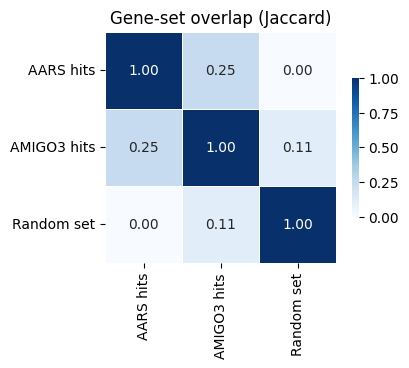

In [8]:
# Feature 5: overlap analysis between gene sets from different perturbations
# (Using toy sets for illustration; in practice, fill with DE-significant genes)
de_sets = {
    'AARS hits':  {'ATF4', 'DDIT3', 'ASNS', 'EIF2AK4', 'SLC7A5'},
    'AMIGO3 hits': {'ATF4', 'DDIT3', 'CDK4', 'CDKN1A', 'EGFR'},
    'Random set': {'BRCA1', 'TP53', 'KRAS', 'EGFR', 'MYC'},
}

result = cx.tl.compute_overlap(de_sets)
print('Jaccard matrix:')
print(result.jaccard_matrix.round(3))
print('\nSet sizes:', result.set_sizes.to_dict())

ax = cx.pl.overlap_heatmap(result, metric='jaccard', title='Gene-set overlap (Jaccard)')

## 3. Quality control

The `cx.pp` preprocessing namespace mirrors Scanpy's API. Each function returns a new `cx.AnnData` object backed by an `.h5ad` file on disk.

In [9]:
qc_result = cx.quality_control_summary(
    adata_ro,
    perturbation_column='perturbation',
    min_genes=5,
    min_cells_per_perturbation=5,
    output_dir=OUTPUT_DIR,
    data_name='tutorial',
)
qc_preview = pd.DataFrame(
    {
        'perturbation': adata_ro.obs['perturbation'],
        'qc_pass': qc_result.cell_mask,
    }
)
adata_ro = qc_result.filtered
print(f"QC result: {qc_result.cell_mask.sum()} / {len(qc_result.cell_mask)} cells passed")
qc_preview.head(5)

[cx] pp.qc_summary: Reading ../../data/Adamson_subset.h5ad
[cx] resolve_control_label: Inferred control label 'control'
[cx] pp.qc_summary: Saving → tutorial_outputs/tutorial_cx_filtered.h5ad
[cx] pp.qc_summary: Strategy — in-memory (0.0 GB, estimated 0.2 GB in memory)
[cx] pp.qc_summary: Done  1716/1716 cells kept (100%), 9238/11630 genes kept (79%), 3/3 perturbations kept (100%)
QC result: 1716 / 1716 cells passed


,perturbation,qc_pass
Cell_barcodes,,
AAACATACAAGATG-1,control,True
AAACATTGCATTGG-1,control,True
AAACGGCTAATGCC-1,AMIGO3,True
AAAGACGAACTCAG-1,control,True
AAAGAGACTCGCCT-1,control,True


### Aggressive-filtering warning

crispyx warns when a filtering step drops more than half the data -- often a sign of a misconfigured threshold. The Adamson subset above passes QC cleanly, so here is a deliberately strict `min_genes` cutoff on the same data to show what that warning looks like:

In [10]:
# Deliberately strict threshold to demonstrate the aggressive-filtering warning.
# Captured and printed rather than let through, so the recorded output shows the
# warning itself instead of this machine's path to qc.py.
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    _ = cx.pp.filter_cells(adata_ro, min_genes=4200)

for warning in caught:
    print(f'{warning.category.__name__}: {warning.message}')

[cx] pp.filter_cells: Done  330/1716 cells kept (19%)


## 4. Subsampling and downsampling

Datasets are sometimes larger than a particular analysis needs, or imbalanced across perturbations/batches in ways that confound comparisons (for example, a screen with many more cells per perturbation, or much greater sequencing depth per cell, than the dataset you want to compare it against). `cx.pp.subsample` and `cx.pp.downsample_counts` reduce scale along two different, composable axes, both streaming and without materialising the full matrix:

- **`cx.pp.subsample`** decides *which cells survive*. Stratify by one or more `obs` columns with `groupby`, and draw either an exact count (`n`) or a proportion (`frac`) independently within each stratum. `unit="cell"` (default) draws individual cells; passing an `obs` column name instead (e.g. `unit="batch"`) switches to **cluster sampling** — a chosen unit's cells are kept in full and an unchosen unit's cells are dropped in full, useful when a dataset has many batches and the goal is to reduce how many batches are processed, not just how many cells within them. `drop_insufficient` controls what happens to a stratum smaller than the requested count: drop it entirely (default), or keep it in full.
- **`cx.pp.downsample_counts`** decides *how many counts survive within* a surviving cell — it thins each cell's total UMI/read count down to a target via sampling without replacement (the same distribution `scanpy.pp.downsample_counts(..., replace=False)` produces, computed natively so this stays a crispyx-only dependency), useful for equalising sequencing depth before comparing cells or datasets.

Both operate on `.obs` metadata or raw counts respectively, so run them **before** normalisation.

In [11]:
# Stratified subsample: cap every perturbation group at n=200 cells each
# (a group smaller than that would be kept in full since drop_insufficient=False).
# Written to a separate file -- adata_ro itself is untouched, so the rest of
# this tutorial keeps using the full QC-filtered dataset.
adata_sub = cx.pp.subsample(
    adata_ro,
    n=200,
    groupby='perturbation',
    drop_insufficient=False,
    random_state=0,
    data_name='tutorial_subsample',
)
print(f"Subsampled shape: {adata_sub.shape}")
adata_sub.obs.load()['perturbation'].value_counts()

[cx] pp.subsample: Done  600/1716 cells kept (35%) across 3 stratum/strata (unit='cell')
Subsampled shape: (600, 9238)


perturbation
AARS       200
AMIGO3     200
control    200
Name: count, dtype: int64

In [12]:
# Downsample counts: thin every cell's total UMI count down to a target,
# leaving cells already at or below the target unchanged. Runs on raw counts
# (adata_ro is still pre-normalisation here), so this is the right point in
# the pipeline for it -- do it before cx.pp.normalize_total_log1p, not after.
import numpy as np

lib_sizes = np.asarray(adata_ro.to_memory().X.sum(axis=1)).ravel()
target = int(np.median(lib_sizes))
print(f"Library size before: median={np.median(lib_sizes):.0f}, max={lib_sizes.max():.0f}")

adata_ds = cx.pp.downsample_counts(
    adata_ro,
    counts_per_cell=target,
    random_state=0,
    data_name='tutorial_downsample',
)
lib_after = np.asarray(adata_ds.to_memory().X.sum(axis=1)).ravel()
print(f"Library size after:  median={np.median(lib_after):.0f}, max={lib_after.max():.0f}")

Library size before: median=14508, max=44938
[cx] pp.downsample_counts: Saving → tutorial_outputs/tutorial_downsample_cx_downsample_counts.h5ad


pp.downsample_counts: 100%|██████████| 1/1 [00:00<00:00,  2.30chunk/s]

[cx] pp.downsample_counts: Done  858/1716 cells thinned to <= 14508 counts
Library size after:  median=14505, max=14508


## 5. Streaming normalisation

For large datasets that would OOM during normalisation, use the streaming preprocessing function. This is the equivalent of `scanpy.pp.normalize_total()` + `scanpy.pp.log1p()` but processes data in chunks.

In [13]:
# Create a normalized + log1p version of the QC-filtered data (streaming)
# This works on huge datasets without loading into memory
adata_norm = cx.pp.normalize_total_log1p(
    adata_ro,  # Pass the AnnData object directly (same as other cx.pp functions)
    output_dir=OUTPUT_DIR,
    data_name='tutorial',
    target_sum=1e4,  # Same as scanpy default
    verbose=True,
)

# Verify the output - adata_norm is a read-only AnnData wrapper
print(f"Shape: {adata_norm.shape}")
print(f"First 3 cells, first 3 genes:\n{adata_norm.to_memory().X[:3, :3].toarray()}")

[cx] pp.normalize_total_log1p: Saving → tutorial_outputs/tutorial_cx_normalized_log1p.h5ad
[cx] pp.normalize_total_log1p: Done  1716 cells × 9238 genes
Shape: (1716, 9238)
First 3 cells, first 3 genes:
[[0.75838053 0.         0.        ]
 [0.49522132 0.         0.        ]
 [1.4766263  0.         0.5161892 ]]


## 6. Dimension reduction

PCA streams the cells from the file twice (fit, then project) and writes `X_pca` back a chunk at a time, so its memory grows with the number of cells only by an 8-byte row index per cell.

- **Highly variable genes first.** PCA uses `var['highly_variable']` when it is present; without it, PCA runs on every gene.
- **Method.** `method='auto'` takes the exact `covariance` method whenever its peak (chiefly the gene × gene matrix, 32 MB for 2,000 genes) fits in half the memory budget, and the approximate `incremental` method only when it does not. `uns['pca']` records the method and chunk used.
- **Neighbours and UMAP** work on the embedding in memory.

The peak memory of each step is in the *Memory model* section of [Working with large data](../large_data.rst).

In [14]:
# Highly variable genes on the log-normalised data, from the control cells
# (mean_dispersion suits log1p data; seurat_v3 expects raw counts)
cx.pp.highly_variable_genes(
    adata_norm,
    flavor='mean_dispersion',
    n_top_genes=2000,
    perturbation_column='perturbation',
)

[cx] pp.highly_variable_genes: Reading tutorial_outputs/tutorial_cx_normalized_log1p.h5ad
[cx] resolve_control_label: Inferred control label 'control'


Computing gene moments:   0%|          | 0/1 [00:00<?, ?it/s]

[cx] pp.highly_variable_genes: Done  2000/9238 genes marked highly variable


In [15]:
# Streaming PCA on the highly variable genes; results are written to the h5ad file
cx.pp.pca(adata_norm, n_comps=20)

pca_info = adata_norm.uns['pca'].load()
print(f"PCA embeddings shape: {adata_norm.obsm['X_pca'].shape}")
print(f"Method: {pca_info['method']}, chunk: {pca_info['chunk_size']} cells, "
      f"genes used: {int(adata_norm.var['highly_variable'].sum())}")
print(f"Variance explained (first 5): {pca_info['variance_ratio'][:5].round(4)}")

# Build the KNN graph from the PCA embedding (also written to the h5ad file)
cx.pp.neighbors(adata_norm, n_neighbors=10, method='sklearn')

print(f"KNN distances shape: {adata_norm.obsp['distances'].shape}")
print(f"Number of connections: {adata_norm.obsp['connectivities'].nnz}")

Computing covariance:   0%|          | 0/1716 [00:00<?, ?cells/s]

Transforming data:   0%|          | 0/1716 [00:00<?, ?cells/s]

PCA embeddings shape: (1716, 20)
Method: covariance, chunk: 1716 cells, genes used: 2000
Variance explained (first 5): [0.051  0.0283 0.0234 0.0142 0.012 ]
KNN distances shape: (1716, 1716)
Number of connections: 25392


### PCA visualization

The `cx.pl` namespace provides Scanpy-style plotting wrappers:
- `cx.pl.pca()`: Scatter plot of PCA embeddings
- `cx.pl.pca_variance_ratio()`: Explained variance per component
- `cx.pl.pca_loadings()`: Gene loadings for top components

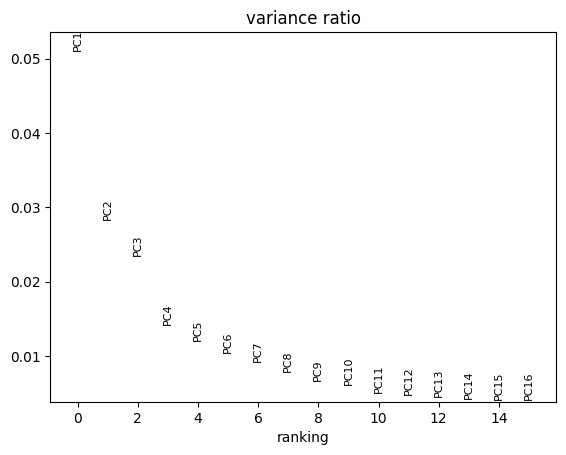

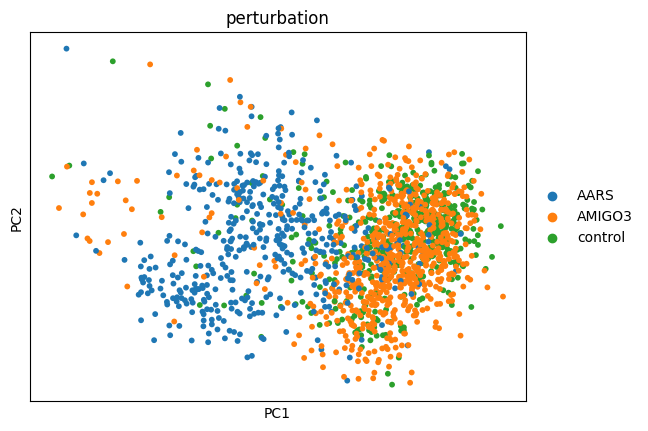

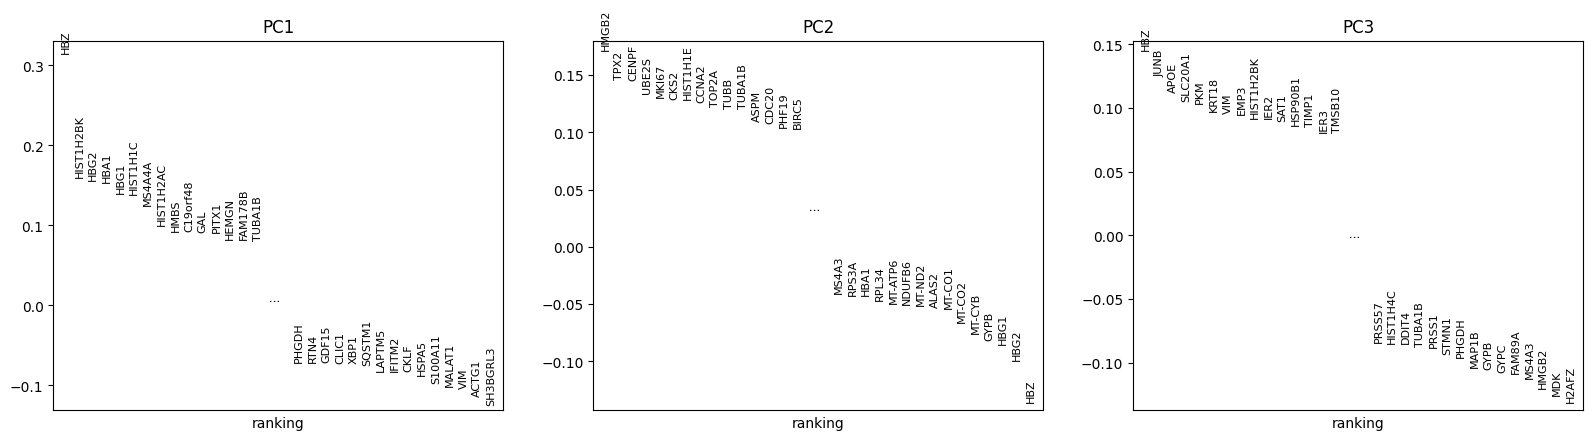

In [16]:
# Plot PCA variance explained
cx.pl.pca_variance_ratio(adata_norm, n_pcs=15)

# Plot PCA scatter colored by perturbation
cx.pl.pca(adata_norm, color='perturbation', components='1,2')

# Plot gene loadings for first 3 components
cx.pl.pca_loadings(adata_norm, components=[1, 2, 3])

### UMAP visualization

`cx.tl.umap()` uses the neighbour graph from `cx.pp.neighbors()`, so it loads only that graph and the PCA embedding, not the expression matrix: about 6 KB per cell (measured at 50 components and 15 neighbours).

UMAP embedding shape: (1716, 2)


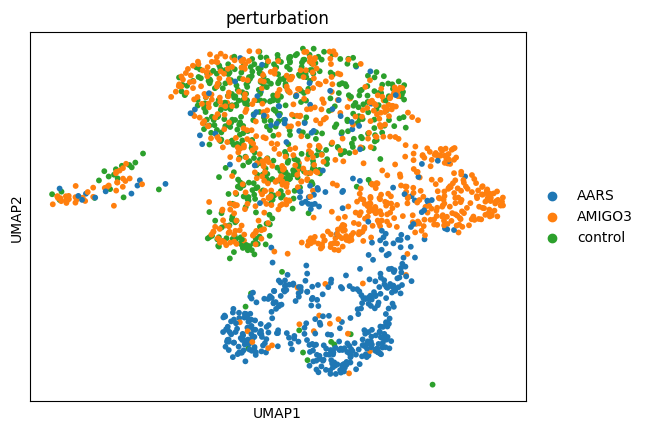

In [17]:
# Compute UMAP from neighbor graph (memory-efficient)
cx.tl.umap(adata_norm, min_dist=0.5, spread=1.0)

# Check UMAP results
print(f"UMAP embedding shape: {adata_norm.obsm['X_umap'].shape}")

# Plot UMAP colored by perturbation
cx.pl.umap(adata_norm, color='perturbation')

## 7. Pseudo-bulk with `cx.pb`

`cx.pb` separates two different jobs:

- **`cx.pb.aggregate`** returns an *absolute* profile per group. No reference is
  involved. Include `batch` in `groupby` to keep one profile per perturbation and
  batch, which gives replicate-aware input for downstream models.
- **`cx.pb.normalized_effects`** returns a *contrast* against a reference, library-size
  normalised, in one streaming pass. Pass `batch_column=` on multi-batch data to
  compute the effect within each batch and combine with harmonic weights.
- **`cx.pb.effects`** is the same contrast but on whatever scale its input already
  carries, and it accepts a saved `cx.pb.aggregate` artifact so profiles can be reused
  without re-reading the cell matrix.

This dataset has no batch column, so the calls below are the single-batch case.

`cx.pb.aggregate` needs an explicit `method`: `'sum'` gives the raw-count sums that
count models (DESeq2, `nb_glm_test`) need, `'mean_log1p'` the mean of log1p values for
log-scale contrasts. Each profile is named by its group key (values joined with `|` for
several `groupby` columns), and `obs` keeps every input column that is constant within
a profile -- donor covariates, for instance -- next to the cell counts `n_cells`.


In [18]:
profiles = cx.pb.aggregate(
    adata_ro,
    groupby='perturbation',
    method='mean_log1p',  # required: 'sum' for count models, 'mean_log1p' for log-scale contrasts
    output_dir=OUTPUT_DIR,
    data_name='tutorial',
)
print(f"Absolute profiles: {profiles.shape}")
# Rows are named by their group; obs columns constant within each profile
# (dataset, celltype) are carried over, per-cell ones (n_genes) are not.
profiles.obs.head()

[cx] pb.aggregate: chunk_size=4096 (auto)
[cx] pb.aggregate: detected count data; applying log1p before averaging
[cx] pb.aggregate accumulator: estimated disk usage: 221.7 KB (3.7 TB free)
[cx] pb.aggregate: estimated disk usage: 243.9 KB (3.7 TB free)


pb.aggregate: 100%|██████████| 1/1 [00:00<00:00, 10.49chunk/s]

[cx] pb.aggregate: obs columns that vary within a profile are not carried over: ['n_genes']
[cx] pb.aggregate: X written dense
[cx] pb.aggregate: 3 profiles × 9238 genes
[cx] pb.aggregate: Saving → tutorial_outputs/tutorial_cx_pseudobulk_mean_log1p.h5ad
Absolute profiles: (3, 9238)


,perturbation,dataset,celltype,n_cells,n_cells_aggregated,sampled_with_replacement
pseudobulk_id,,,,,,
control,control,Adamson,K562,500,500,False
AMIGO3,AMIGO3,Adamson,K562,750,750,False
AARS,AARS,Adamson,K562,466,466,False


In [19]:
# Contrast against the control, normalised internally.
# On multi-batch data add batch_column='batch' for the batch-corrected effect.
effects = cx.pb.normalized_effects(
    adata_ro,
    groupby='perturbation',
    method='mean_log1p',
    output_dir=OUTPUT_DIR,
    data_name='tutorial',
)
print(f"Effects: {effects.shape}  layers: {list(effects.backed.layers)}")
effects.obs.head()

[cx] pb.normalized_effects: Reading tutorial_outputs/tutorial_cx_filtered.h5ad
[cx] pb.normalized_effects: chunk_size=4096 (auto)
[cx] resolve_control_label: Inferred control label 'control'
[cx] pb.normalized_effects: estimated disk usage: 650.4 KB (3.7 TB free)
[cx] pb.normalized_effects: 2 perturbations × 9238 genes
[cx] pb.normalized_effects: Saving → tutorial_outputs/tutorial_cx_normalized_effects.h5ad
Effects: (2, 9238)  layers: ['perturbation_profile', 'standard_error', 'standard_error_robust']


,perturbation
perturbation,
AMIGO3,AMIGO3
AARS,AARS


## 8. Differential expression with `cx.tl`

Run a Wilcoxon test that mirrors ``scanpy.tl.rank_genes_groups``. ``cx.AnnData.uns`` entries also provide ``preview`` and ``load`` helpers.

### Checking disk usage before a large run

Before running an expensive test, `cx.estimate_disk_usage` (also available as `cx.tl.estimate_disk_usage`) reports how much disk space it will need without touching the expression matrix -- useful for capacity planning before committing to a run on a shared cluster. On this small tutorial subset the footprint is negligible, but the same call on a genome-wide screen reports a meaningful number.

In [20]:
usage = cx.tl.estimate_disk_usage(
    'wilcoxon_test',
    adata_norm.path,
    perturbation_column='perturbation',
)
for location, estimate in usage.items():
    print(f'{location}: {estimate}')

[cx] resolve_control_label: Inferred control label 'control'
output: 1.9 MB required, 3.7 TB free at tutorial_outputs [OK]


In [21]:
adata_ro = cx.tl.rank_genes_groups(
    adata_norm,  # Wilcoxon expects log-normalized data
    perturbation_column='perturbation',
    method='wilcoxon',
    output_dir=OUTPUT_DIR,
    data_name='tutorial',
)

# Preview a tidy DE table using plotting helper (no scanpy_format needed)
group = adata_ro.obs.load()['perturbation'].astype(str).unique()[0]
cx.pl.rank_genes_groups_df(adata_ro, group=group, n_genes=10).head()


[cx] resolve_control_label: Inferred control label 'control'
[cx] wilcoxon_test: chunk_size=4096 (auto)
[cx] wilcoxon_test: format_mismatch_policy='auto': streaming from the source (3 chunks x 48.3 MB at 8.8 GB/s = 0.01 s per re-read, 0.0 s of re-reading beyond the first chunk)
[cx] wilcoxon_test: estimated disk usage: 1.9 MB (3.7 TB free)


Wilcoxon DE (gene chunks): 100%|██████████| 3/3 [00:00<00:00,  5.86perturbation/s]

[cx] wilcoxon_test: 3 gene chunks: read 0.0 s, compute 0.3 s, write 0.2 s
[cx] Wilcoxon DE: 2 perturbations complete, mean 9238/9238 genes tested (100%)
[cx] wilcoxon_test: Saving → tutorial_outputs/tutorial_cx_wilcoxon.h5ad


,names,scores,logfoldchanges,pvals,pvals_adj,pts,pts_rest,group
0,SET,-10.899647,-0.506634,1.157049e-27,8.419143e-24,0.990667,0.988,AMIGO3
1,MT-CO2,10.858218,0.402062,1.822720e-27,8.419143e-24,0.998667,0.998,AMIGO3
2,RPS27A,10.551140,0.267033,5.018421e-26,1.022991e-22,1.000000,1.000,AMIGO3
3,EIF1,10.539785,0.288907,5.662821e-26,1.022991e-22,1.000000,1.000,AMIGO3
4,MT-CYB,10.534347,0.327073,5.999814e-26,1.022991e-22,0.998667,0.998,AMIGO3


Use ``load`` to materialise the complete differential expression tables for downstream analysis.

In [22]:
group = adata_ro.obs.load()['perturbation'].astype(str).unique()[0]
top_df = cx.pl.rank_genes_groups_df(adata_ro, group=group, n_genes=5)
print(f"Top 5 DE genes for perturbation '{group}':")
top_df[['names', 'logfoldchanges', 'pvals_adj']]


Top 5 DE genes for perturbation 'AMIGO3':


,names,logfoldchanges,pvals_adj
0,SET,-0.506634,8.419143e-24
1,MT-CO2,0.402062,8.419143e-24
2,RPS27A,0.267033,1.022991e-22
3,EIF1,0.288907,1.022991e-22
4,MT-CYB,0.327073,1.022991e-22


The ``cx.AnnData`` handles close themselves when their Python objects go out of scope, so no explicit cleanup is required.

## 9. NB-GLM differential expression

For more sophisticated differential expression analysis, crispyx provides a negative binomial GLM method that models count data directly. This is especially useful when you need to incorporate covariates or want more accurate statistical modeling.

Note: NB-GLM operates on **raw counts** (not log-normalized data), so we use the QC-filtered dataset directly.

In [23]:
# Run NB-GLM test on raw counts
# First, reload the QC-filtered dataset (not log-normalized)
qc_path = OUTPUT_DIR / 'tutorial_cx_filtered.h5ad'
adata_qc = cx.read_h5ad_ondisk(qc_path)

adata_nb = cx.tl.rank_genes_groups(
    adata_qc,
    perturbation_column='perturbation',
    method='nb_glm',
    output_dir=OUTPUT_DIR,
    data_name='tutorial_nb',
)
group = adata_nb.obs.load()['perturbation'].astype(str).unique()[0]
cx.pl.rank_genes_groups_df(adata_nb, group=group, n_genes=5).head()


AnnData object with n_obs × n_vars = 1716 × 9238 backed at 'tutorial_outputs/tutorial_cx_filtered.h5ad'
    obs: 'perturbation', 'n_genes', 'dataset', 'celltype'
    var: 'Ensembl_ID', 'gene_symbols'
First obs rows:
                 perturbation  n_genes  dataset celltype
Cell_barcodes                                           
AAACATACAAGATG-1      control     2914  Adamson     K562
AAACATTGCATTGG-1      control     3999  Adamson     K562
AAACGGCTAATGCC-1       AMIGO3     3947  Adamson     K562
AAAGACGAACTCAG-1      control     2713  Adamson     K562
AAAGAGACTCGCCT-1      control     3678  Adamson     K562
First var rows:
                  Ensembl_ID gene_symbols
Gene_symbol                              
NOC2L        ENSG00000188976        NOC2L
KLHL17       ENSG00000187961       KLHL17
HES4         ENSG00000188290         HES4
ISG15        ENSG00000187608        ISG15
AGRN         ENSG00000188157         AGRN
[cx] nb_glm_test: min_mu=1e-06 (61% of a sample of the counts are zero)
[cx

NB-GLM DE: 100%|██████████| 2/2 [00:00<00:00,  2.95perturbation/s]

[cx] NB-GLM DE: 2/2 perturbations complete, mean 9238/9238 genes tested (100%)
[cx] nb_glm_test: Saving → tutorial_outputs/tutorial_nb_cx_nb_glm.h5ad


,names,scores,logfoldchanges,pvals,pvals_adj,pts,pts_rest,group
0,RPS27A,11.701474,0.273528,1.252581e-31,1.157134e-27,1.000000,1.000,AMIGO3
1,EIF1,11.600152,0.299318,4.113470e-31,1.900012e-27,1.000000,1.000,AMIGO3
2,MT-CYB,11.308648,0.365223,1.189072e-29,3.661550e-26,0.998667,0.998,AMIGO3
3,COX5A,10.902612,0.330253,1.119957e-27,2.586541e-24,1.000000,0.992,AMIGO3
4,UQCRH,10.657649,0.209627,1.606061e-26,2.967358e-23,1.000000,0.998,AMIGO3


## 10. LFC shrinkage with apeGLM

Apply adaptive shrinkage to log-fold changes using the apeGLM method. This shrinks noisy/uncertain LFCs toward zero while preserving large effects, following DESeq2/PyDESeq2 best practices.

The two-step workflow (NB-GLM → shrink_lfc) gives you control over when shrinkage is applied and allows you to compare shrunk vs unshrunk results.

In [24]:
# Apply LFC shrinkage to NB-GLM results
nb_result_path = adata_nb.path

shrunk = cx.tl.shrink_lfc(
    nb_result_path,
    prior_scale_mode='global',  # Use global prior across all perturbations
)

# Compare shrunk vs raw LFC for a perturbation
import anndata
shrunk_adata = anndata.read_h5ad(shrunk.result_path)
print("Shrunk vs Raw LFC (first 5 genes, first perturbation):")
print(f"  Shrunk LFC: {shrunk_adata.X[0, :5]}")
print(f"  Raw LFC:    {shrunk_adata.layers['logfoldchange_raw'][0, :5]}")


[cx] shrink_lfc: estimated disk usage: 2.5 MB (3.7 TB free)
[cx] shrink_lfc: Saving → tutorial_outputs/tutorial_nb_cx_nb_glm_shrunk.h5ad
[cx] shrink_lfc: Done  2 perturbations × 9238 genes (method='stats')
Shrunk vs Raw LFC (first 5 genes, first perturbation):
  Shrunk LFC: [-0.04456859 -0.0500326  -0.01965117 -0.01293677 -0.15599231]
  Raw LFC:    [-0.04858927 -0.15000203 -0.0240503  -0.01507098 -0.27033117]


The shrunk LFC values are typically smaller in magnitude for genes with high uncertainty, while large, well-supported effects are preserved. This improves downstream ranking and visualization.

## 11. Plotting (Scanpy-style)

crispyx provides `cx.pl` helpers for plotting on-disk results. The examples below mirror
Scanpy style while keeping the expression matrix on disk.


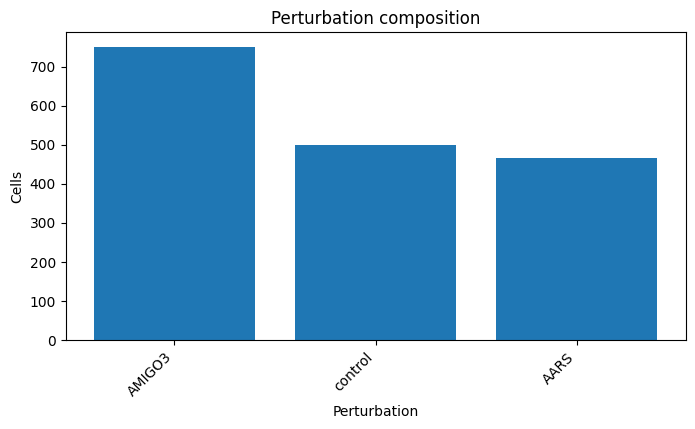

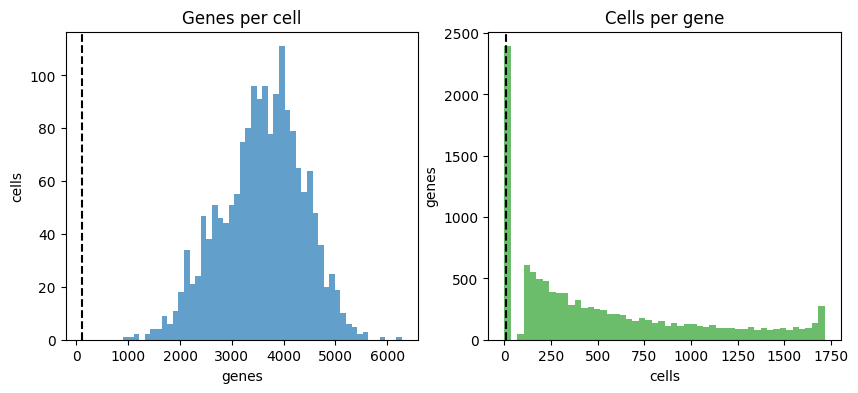

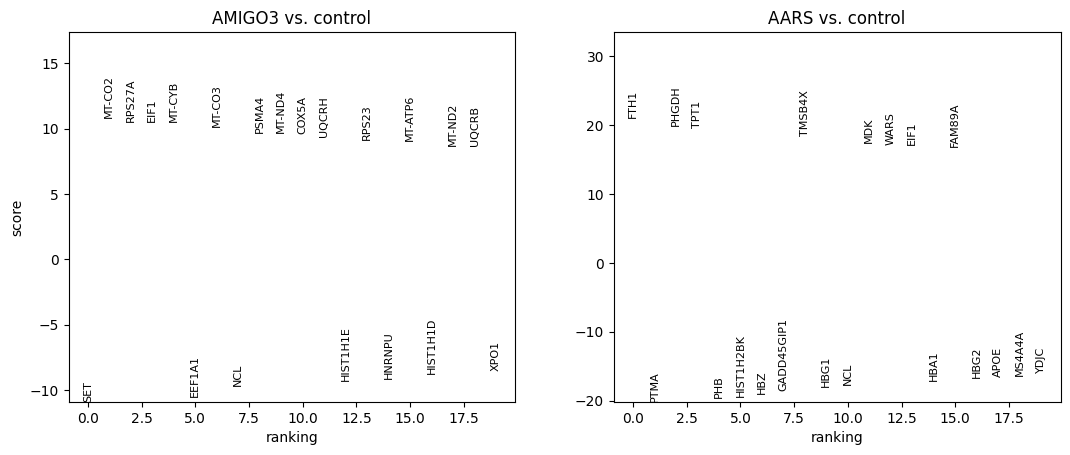

<Axes: title={'center': 'MA plot: AMIGO3 vs control'}, xlabel='log1p(mean expression)', ylabel='log2FC'>

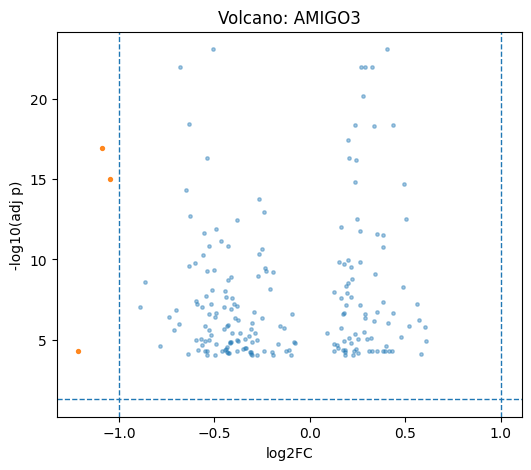

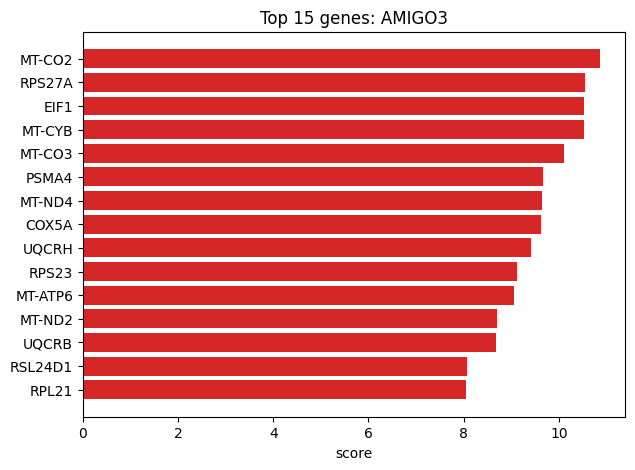

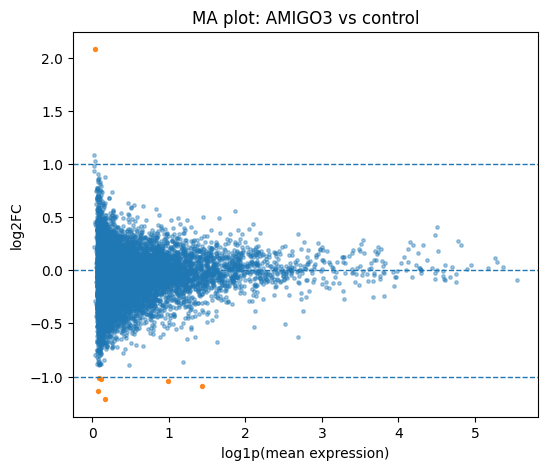

In [25]:
# QC plots
cx.pl.qc_perturbation_counts(
    data=adata_qc,
    perturbation_column='perturbation',
    cell_mask=qc_result.cell_mask,
)
cx.pl.qc_summary(qc_result, min_genes=100, min_cells_per_gene=10)

# Rank genes groups plot
cx.pl.rank_genes_groups(adata_ro, n_genes=20, sharey=False)

# Volcano / top genes
plot_group = adata_ro.obs.load()['perturbation'].astype(str).unique()[0]
df = cx.pl.rank_genes_groups_df(adata_ro, group=plot_group, n_genes=200)
cx.pl.volcano(de_df=df, group=plot_group)
cx.pl.top_genes_bar(de_df=df, group=plot_group, topn=15)

# MA plot (raw counts from QC-filtered data)
try:
    control_label = adata_ro.uns['control_label'].load()
except KeyError:
    control_label = 'control'
cx.pl.ma(
    data=adata_qc,
    de_result=adata_ro,
    group=plot_group,
    reference=control_label,
    perturbation_column='perturbation',
    mean_mode='raw',
)
